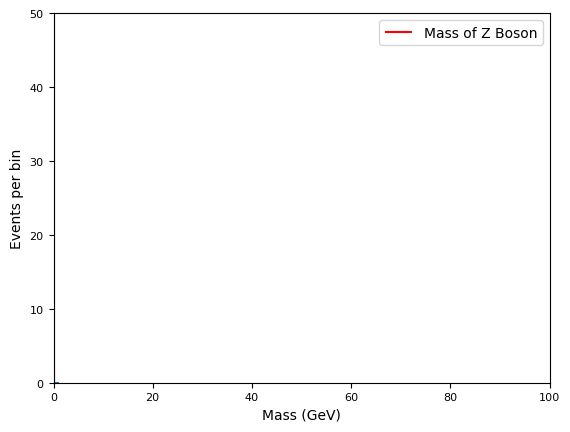

In [ ]:
""" This code does not take into account the fact 
that b mesons are unstable and also finally 
decay into other particles."""

import pythia8
import fastjet
import numpy as np
import matplotlib.pyplot as plt


file = pythia8.Pythia()
file.readString("Beams:frameType = 4") # Option 4 = Read LHE file
file.readString("Beams:LHEF = unweighted_events.lhe")
file.init()

B_Meson=[511, 521, 10511, 10521, 513, 523, 10513, 10523, 
    20513, 20523, 515, 525, 531, 10531, 533, 10533, 
    20533, 535, 541, 10541, 543, 10543, 20543, 545]     #pdg id's of all b mesons

m_Z=[]
while file.next():      #produces showers of particles
    final_event_prt=[]
    i=0             #for providing index to each final state particle
    for prt in file.event:
        if prt.status()>0:
            four_p=fastjet.PseudoJet(prt.px(), prt.py(), prt.pz(), prt.e()) #storing 4-momentum
            four_p.set_user_index(i)    #provided index with PseudoJet object
            final_event_prt.append(four_p)      #list of 4-momenta of final particles
        i+=1

    jetdef = fastjet.JetDefinition(fastjet.antikt_algorithm, 0.4)   #defines jet recontruction algorithm with R=0.4
    cluster = fastjet.ClusterSequence(final_event_prt, jetdef)      #produces clusters of jets acc in the form of a tuple
    jets = list(cluster.inclusive_jets(ptmin=20.0))   #converts tuple to list of reconstructed jets with pT>20 GeV

    b_jets=[]   #list of jets which have b mesons
    for jet in jets:
        prt_list=jet.constituents()     #list of partcles in this jet
        for prt in prt_list:
            prt_index=prt.user_index()  #index of that particle which was assigned earlier
            if file.event[prt_index].idAbs() in B_Meson:    #checking its pdg id
                b_jets.append(jet)
                break   #shortens runtime
    if len(b_jets)>=2:
        b_jets.sort(key=lambda j: j.pt(), reverse=True)

        final_four_p=b_jets[0]+b_jets[1]
        m_Z.append(final_four_p.m())

histy, bin_edges = np.histogram(m_Z, bins=70)
bin_centers = 0.5*(bin_edges[1:] + bin_edges[:-1])
mass= bin_centers[np.argmax(histy)]
plt.plot(bin_centers,histy,drawstyle = 'steps-mid')
plt.vlines(mass, 0, 50, colors='red', linestyles='solid', label='Mass of Z Boson')
plt.xlabel('Mass (GeV)', fontsize=10)
plt.ylabel('Events per bin', fontsize=10)
plt.ylim(0,50) #Label y
plt.xlim(0,100)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()










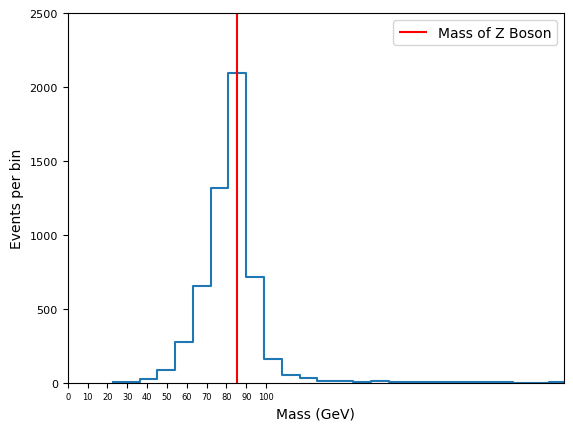

In [ ]:
"""Corrected code which defines a function that checks 
if the final state particles decayed from a b meson 
and uses that to tage jets"""

import pythia8
import fastjet
import numpy as np
import matplotlib.pyplot as plt


file = pythia8.Pythia()
file.readString("Beams:frameType = 4") # Option 4 = Read LHE file
file.readString("Beams:LHEF = unweighted_events.lhe")
file.init()

B_Meson=[511, 521, 10511, 10521, 513, 523, 10513, 10523, 
    20513, 20523, 515, 525, 531, 10531, 533, 10533, 
    20533, 535, 541, 10541, 543, 10543, 20543, 545]     #pdg id's of all b mesons


m_Z=[]
while file.next():      #produces showers of particles
    final_event_prt=[]  #for storing 4-momentum of all final state particles
    i=0             #for providing index to each final state particle
    for prt in file.event:
        if prt.status()>0:
            four_p=fastjet.PseudoJet(prt.px(), prt.py(), prt.pz(), prt.e()) #storing 4-momentum
            four_p.set_user_index(i)    #provided index with PseudoJet object
            final_event_prt.append(four_p)      #list of 4-momenta of final particles
        i+=1

    jetdef = fastjet.JetDefinition(fastjet.antikt_algorithm, 0.4)   #defines jet recontruction algorithm with R=0.4
    cluster = fastjet.ClusterSequence(final_event_prt, jetdef)      #produces clusters of jets acc in the form of a tuple
    jets = list(cluster.inclusive_jets(ptmin=20.0))   #converts tuple to list of reconstructed jets with pT>20 GeV

    def comes_from_b_meson(event, start_index):     #to check if the final state particle decayed from a b meson
        curr_index=start_index
        while curr_index>0:     #the loop breaks when we reach the particle which started the process (Z-boson in this case)
            prt=event[curr_index]       #here prt is a local variable
            if event[curr_index].idAbs() in B_Meson:
                return True
            curr_index=prt.mother1()    #if not true, the loop contunies to track the mothers of subsequent particles
        return False

    

    b_jets=[]   #list of jets which have b mesons
    for jet in jets:        #jets only contain final state particles
        prt_list=jet.constituents()     #list of partcles in this jet
        for prt in prt_list:        #this prt is different from the one defined earlier (prt in jet)
            prt_index=prt.user_index() #index of that particle which was assigned earlier
            if comes_from_b_meson(file.event, prt_index):    #checking if it originated from B meson
                b_jets.append(jet)
                break   #shortens runtime
    if len(b_jets)>=2:      #incase we get more than two jets tagged as b jets
        b_jets.sort(key=lambda j: j.pt(), reverse=True)

        final_four_p=b_jets[0]+b_jets[1]
        m_Z.append(final_four_p.m())

histy, bin_edges = np.histogram(m_Z, bins=70)
bin_centers = 0.5*(bin_edges[1:] + bin_edges[:-1])
mass= bin_centers[np.argmax(histy)]
plt.plot(bin_centers,histy,drawstyle = 'steps-mid')
plt.vlines(mass, 0, 2500, colors='red', linestyles='solid', label='Mass of Z Boson')
plt.xlabel('Mass (GeV)', fontsize=10)
plt.ylabel('Events per bin', fontsize=10)
plt.ylim(0,2500) #Label y
plt.xlim(0,250)
plt.xticks(np.arange(0,101,10),fontsize=6)
plt.yticks(fontsize=8)
plt.legend()
plt.show()








